# Feature Selection for Efficient Text Classification
**Dataset:** 20 Newsgroups (TF-IDF) &nbsp;|&nbsp; **Task:** 20-class text classification

**Question:** Can we reduce the number of input features and make classifiers faster
*without sacrificing* accuracy or Macro-F1?

**Compared:** all features vs. features chosen by six selection methods, across four models.
**Metrics:** Number of Features, Accuracy, Macro-F1, Training Time, Inference Time.

**Verdict rule:** a setup *preserves performance and improves efficiency* if Accuracy and Macro-F1 each
drop by at most **1 point** vs. all features **and** training is at least **1.1x faster**.

> Run all cells top to bottom. The full run takes roughly 20-40 minutes on a laptop
> (Random Forest is the slowest part). Set `FAST = True` for a quick run with 2 models.

In [1]:
import os, sys
sys.path.append(os.path.abspath(".."))      # make `src` importable from notebooks/
import pandas as pd
from src.preprocessing import get_data, describe
from src import evaluation as ev
from src.model import DEFAULT_MODELS, KBEST_METHODS, ALL_METHODS

pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)

DATA_SOURCE = os.environ.get("DATA_SOURCE", "20newsgroups")   # "sample" = tiny smoke test
FAST   = False        # True: 2 models, fewer methods and k values
K      = 3000         # features kept by the top-k methods
LEVELS = [75, 50, 25, 10, 5, 2, 1]   # % of features kept after "all features"
REPEATS = 5           # timing repeats (median); slow models use fewer
MODELS  = DEFAULT_MODELS     # add "kNN" for a fifth model
METHODS = None               # None = all six selection methods
if FAST:
    MODELS  = ["LinearSVC", "NaiveBayes"]
    METHODS = [m for m in ALL_METHODS if m not in ("Mutual Information", "Random Forest")]
    LEVELS, REPEATS = [50, 25, 10, 5, 1], 3
FIG = "../results/figures"; OUT = "../results"

## 1. Dataset

{'train_samples': 11314, 'test_samples': 7532, 'features': 39115, 'classes': 20, 'density_%': 0.1567, 'avg_nonzero_per_doc': 61.3}


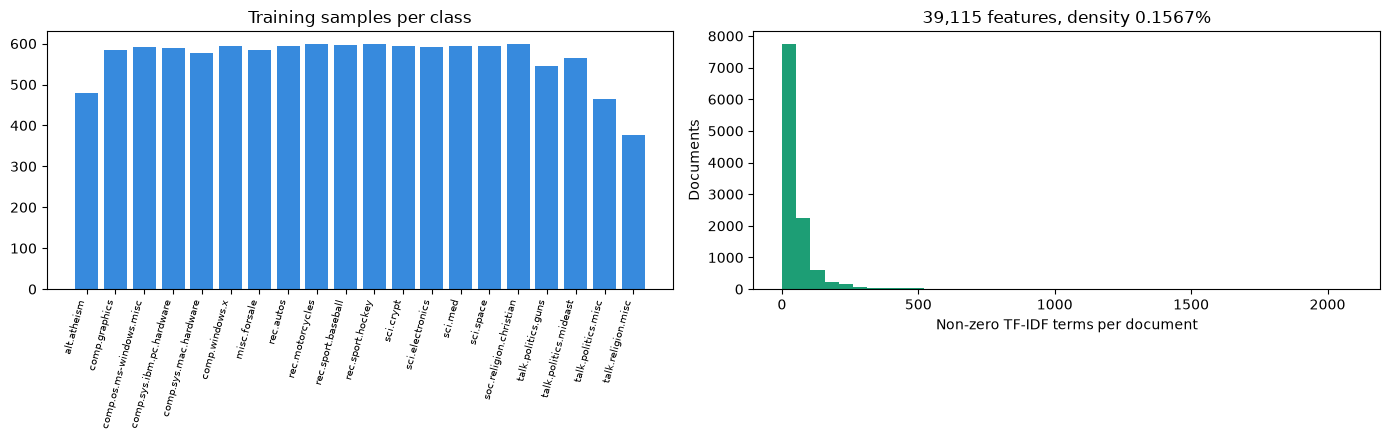

In [2]:
data = get_data(DATA_SOURCE)
print(describe(data))
ev.fig_dataset_overview(data, f"{FIG}/01_dataset_overview.png", show=True);

## 2. Main comparison: all features vs. selected features
Every selector is fitted on the **training set only**. Each selection method scores the features once;
the same selected feature set is then used to train every model. Timings are medians over repeated runs.

In [3]:
main_df, scores, indices = ev.run_main_comparison(data, MODELS, K, REPEATS, METHODS)

[score] Variance Threshold ...
[score] Chi-square ...
[score] ANOVA F-test ...
[score] Mutual Information ...
[score] L1-SVM ...
[score] Random Forest ...
[eval] All features (baseline)            | LinearSVC
[eval] All features (baseline)            | LogisticRegression
[eval] All features (baseline)            | NaiveBayes
[eval] All features (baseline)            | RandomForest
[eval] Variance Threshold (var > 1e-05)   | LinearSVC
[eval] Variance Threshold (var > 1e-05)   | LogisticRegression
[eval] Variance Threshold (var > 1e-05)   | NaiveBayes
[eval] Variance Threshold (var > 1e-05)   | RandomForest
[eval] Chi-square (k=3000)                | LinearSVC
[eval] Chi-square (k=3000)                | LogisticRegression
[eval] Chi-square (k=3000)                | NaiveBayes
[eval] Chi-square (k=3000)                | RandomForest
[eval] ANOVA F-test (k=3000)              | LinearSVC
[eval] ANOVA F-test (k=3000)              | LogisticRegression
[eval] ANOVA F-test (k=3000)             

## 3. Step-down comparison: all features first, then fewer and fewer
Start from **all features (100%)**, then keep 75%, 50%, 25%, 10%, 5%, 2% and 1% of them, ranked by each method.
This shows exactly where performance starts to drop and how efficiency improves at each step.

In [4]:
ladder = ev.run_reduction_ladder(data, scores, main_df, MODELS, LEVELS, repeats=2,
                                 methods=[m for m in KBEST_METHODS if m in scores])
df = ev.add_deltas(pd.concat([main_df, ladder], ignore_index=True))
ev.save_results(df, OUT)                 # also writes results/reduction_ladder.csv
main = df[df.Experiment == "main"]

[sweep] Chi-square         k=29336  | LinearSVC
[sweep] Chi-square         k=29336  | LogisticRegression
[sweep] Chi-square         k=29336  | NaiveBayes
[sweep] Chi-square         k=29336  | RandomForest
[sweep] Chi-square         k=19558  | LinearSVC
[sweep] Chi-square         k=19558  | LogisticRegression
[sweep] Chi-square         k=19558  | NaiveBayes
[sweep] Chi-square         k=19558  | RandomForest
[sweep] Chi-square         k=9779   | LinearSVC
[sweep] Chi-square         k=9779   | LogisticRegression
[sweep] Chi-square         k=9779   | NaiveBayes
[sweep] Chi-square         k=9779   | RandomForest
[sweep] Chi-square         k=3912   | LinearSVC
[sweep] Chi-square         k=3912   | LogisticRegression
[sweep] Chi-square         k=3912   | NaiveBayes
[sweep] Chi-square         k=3912   | RandomForest
[sweep] Chi-square         k=1956   | LinearSVC
[sweep] Chi-square         k=1956   | LogisticRegression
[sweep] Chi-square         k=1956   | NaiveBayes
[sweep] Chi-square        

## 4. Headline table (required format) - primary model: LinearSVC

In [5]:
ev.headline_table(df)

,Setup,Number of Features,Accuracy,Macro-F1,Training Time (s),Inference Time (ms/1000 samples),Selection Time (s),Feature Reduction (%),Acc Change (pts),F1 Change (pts),Train Speedup (x),Inference Speedup (x),Verdict
0,All features (baseline),39115,0.6982,0.6861,1.2254,1.6710,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,-
1,Variance Threshold (var > 1e-05),17094,0.6956,0.6831,1.1050,1.6913,0.1504,56.2981,-0.2655,-0.3009,1.1089,0.9880,Yes
2,Chi-square (k=3000),3000,0.6779,0.6673,1.0077,0.7032,0.0876,92.3303,-2.0313,-1.8793,1.2160,2.3762,No
3,ANOVA F-test (k=3000),3000,0.6641,0.6518,1.1977,0.8532,0.1016,92.3303,-3.4121,-3.4375,1.0231,1.9585,No
4,Mutual Information (k=3000),3000,0.6553,0.6430,1.5411,1.0742,217.0968,92.3303,-4.2884,-4.3083,0.7951,1.5555,No
5,L1-SVM (non-zero weights),400,0.5773,0.5718,0.6926,0.5241,1.6934,98.9774,-12.0951,-11.4296,1.7692,3.1885,No
6,Random Forest (k=3000),3000,0.6524,0.6394,1.5005,1.4716,28.2345,92.3303,-4.5805,-4.6775,0.8167,1.1355,No


## 5. Results across models

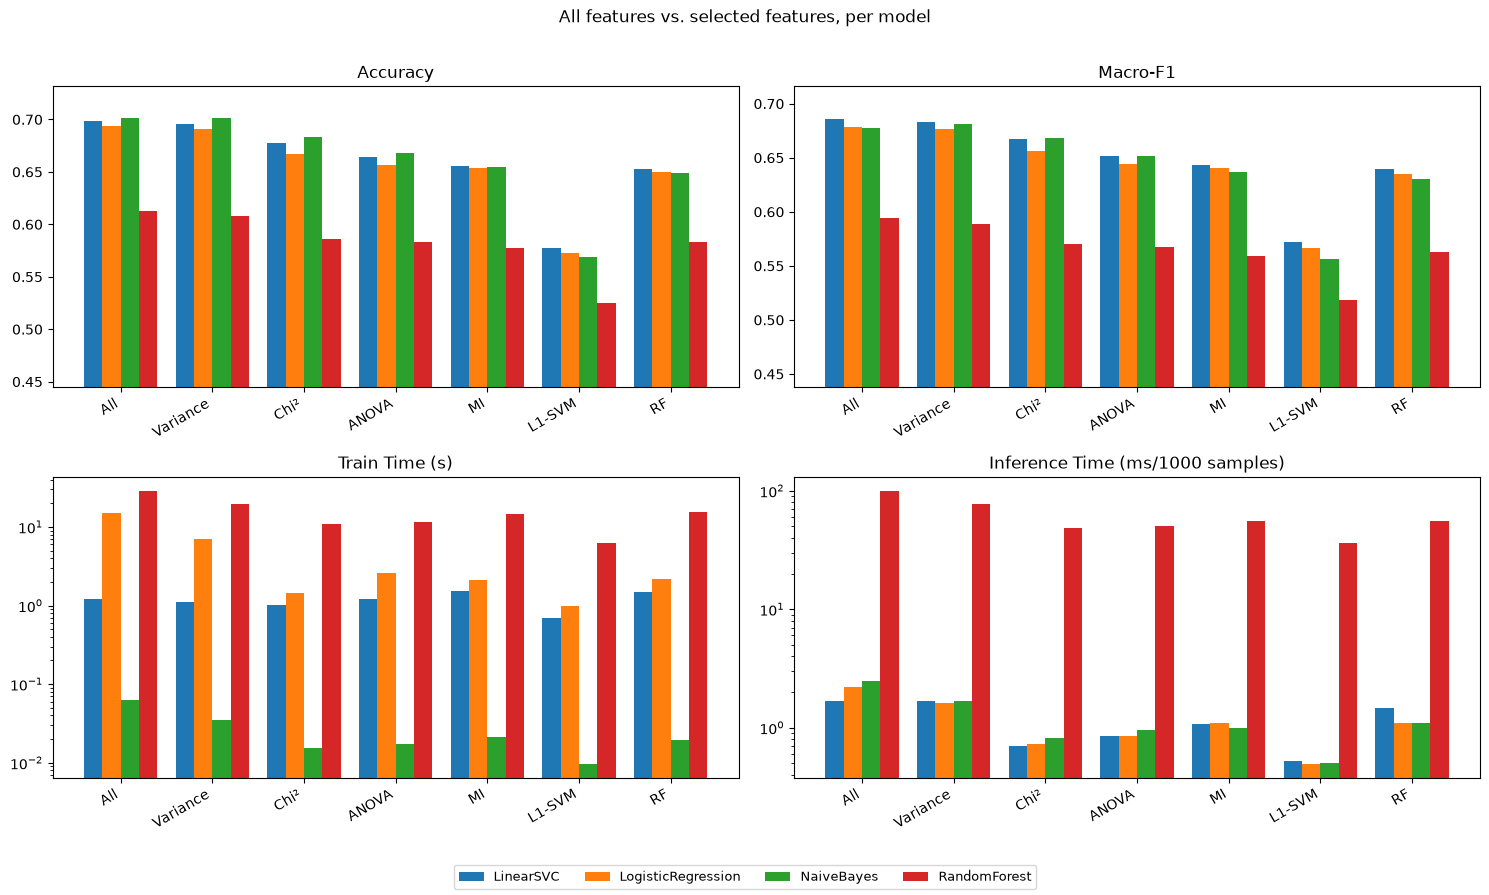

In [6]:
ev.fig_dashboard(df, f"{FIG}/02_metrics_dashboard.png", show=True);

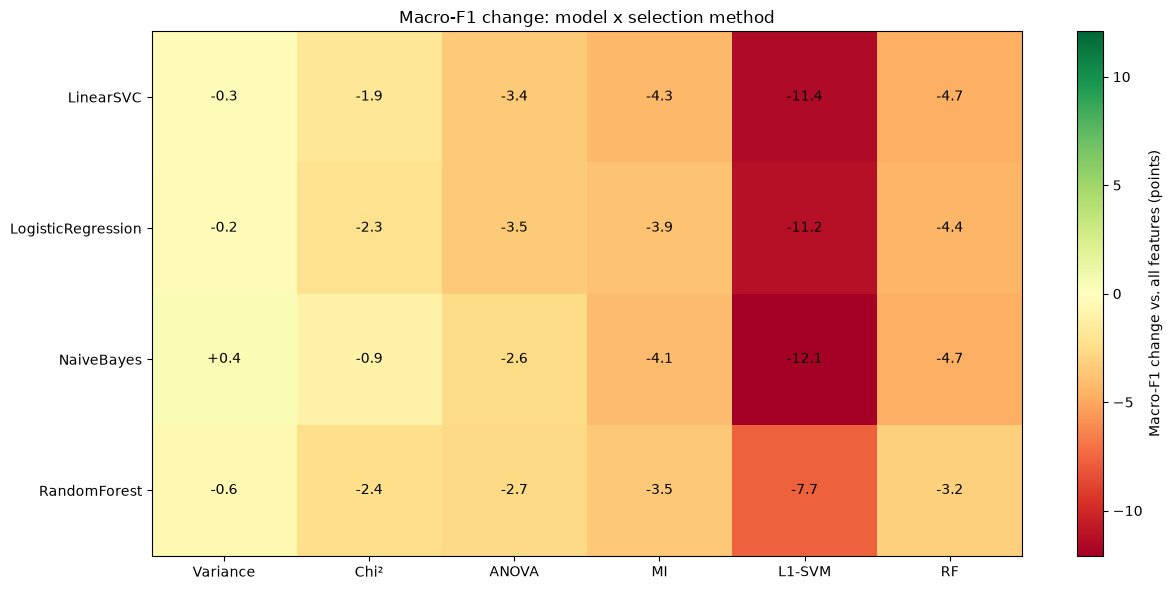

In [7]:
ev.fig_heatmap(df, f"{FIG}/03_model_method_heatmap.png", show=True);

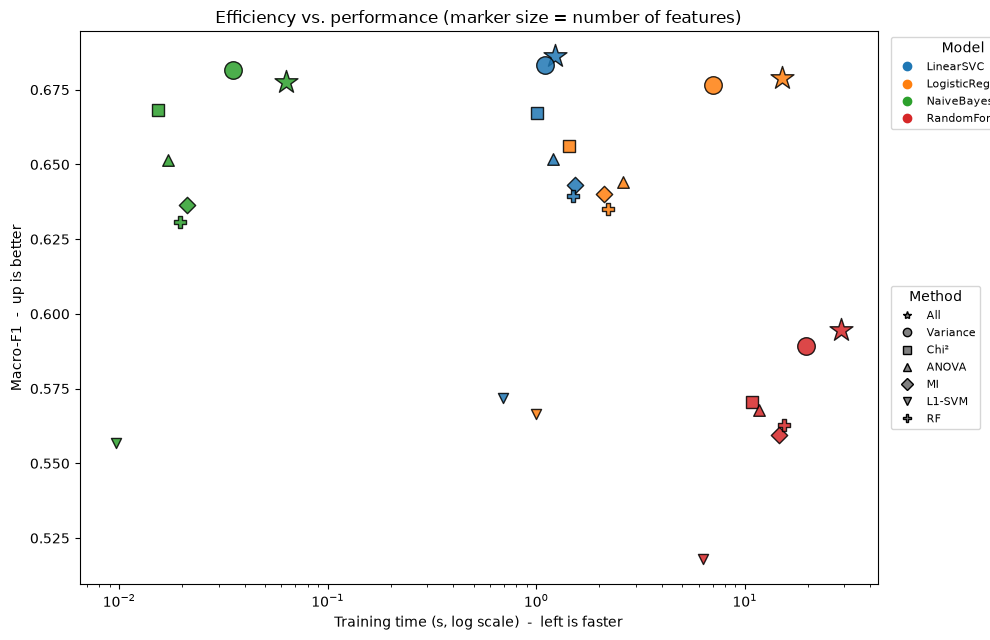

In [8]:
ev.fig_efficiency_scatter(df, f"{FIG}/04_efficiency_scatter.png", show=True);

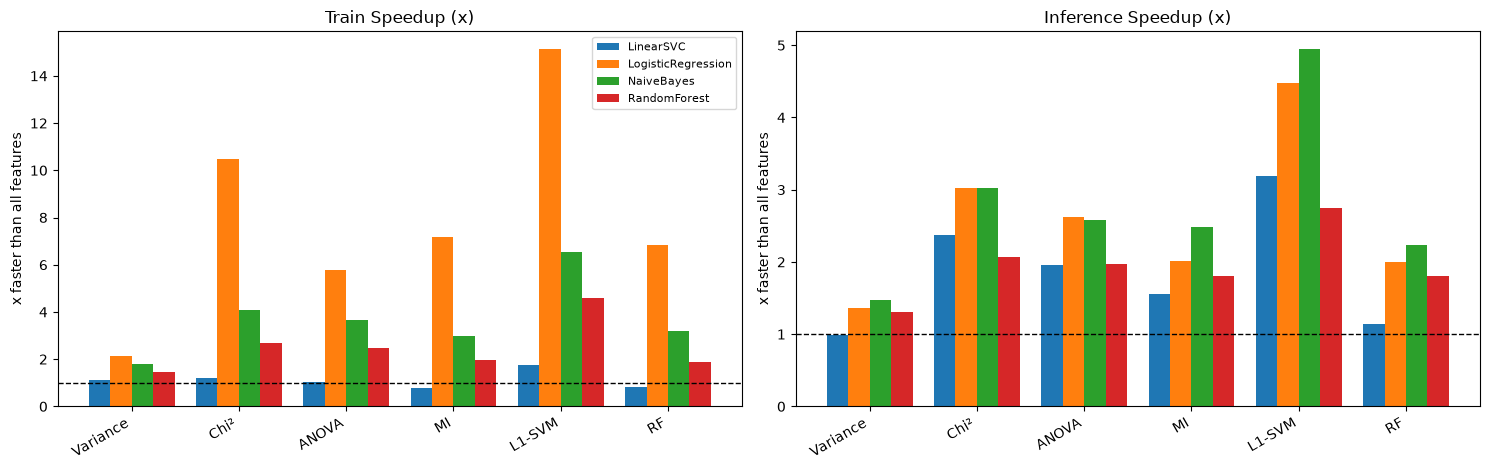

In [9]:
ev.fig_speedup(df, f"{FIG}/06_speedups.png", show=True);

## 6. Where does performance break down? (step-down ladder)
Each table has **all features (100%) on the left**, then fewer and fewer features to the right.

In [10]:
print("Macro-F1 (LinearSVC)"); display(ev.ladder_pivot(df, "LinearSVC", "Macro-F1"))
print("Accuracy (LinearSVC)");  display(ev.ladder_pivot(df, "LinearSVC", "Accuracy"))
print("Training time in seconds (LinearSVC)"); display(ev.ladder_pivot(df, "LinearSVC", "Train Time (s)"))

Macro-F1 (LinearSVC)


,100%,75%,50%,25%,10%,5%,2%,1%
Method,,,,,,,,
Chi-square,0.6861,0.6852,0.6869,0.6834,0.6716,0.6486,0.6247,0.5847
ANOVA F-test,0.6861,0.6847,0.6802,0.6751,0.6612,0.6403,0.6147,0.5752
Mutual Information,0.6861,0.6818,0.6781,0.6710,0.6560,0.6282,0.5852,0.5388
L1-SVM,0.6861,0.6710,0.6487,0.6122,0.5799,0.5781,0.5732,0.5716
Random Forest,0.6861,0.6846,0.6834,0.6720,0.6483,0.6249,0.5802,0.5296


Accuracy (LinearSVC)


,100%,75%,50%,25%,10%,5%,2%,1%
Method,,,,,,,,
Chi-square,0.6982,0.6977,0.6990,0.6965,0.6827,0.6593,0.6186,0.5689
ANOVA F-test,0.6982,0.6973,0.6924,0.6879,0.6731,0.6514,0.6131,0.5652
Mutual Information,0.6982,0.6946,0.6911,0.6834,0.6680,0.6399,0.5956,0.5469
L1-SVM,0.6982,0.6840,0.6610,0.6237,0.5874,0.5851,0.5791,0.5766
Random Forest,0.6982,0.6970,0.6954,0.6848,0.6618,0.6379,0.5911,0.5404


Training time in seconds (LinearSVC)


,100%,75%,50%,25%,10%,5%,2%,1%
Method,,,,,,,,
Chi-square,1.2254,1.3397,1.1699,2.6917,1.1608,1.0560,0.7951,0.6242
ANOVA F-test,1.2254,1.4544,1.0175,2.4718,1.3078,1.1088,0.9671,0.6636
Mutual Information,1.2254,1.2795,1.1924,3.1234,1.6016,1.3062,0.9635,0.7360
L1-SVM,1.2254,1.0164,0.8396,2.0922,1.1408,0.8565,0.7626,0.6562
Random Forest,1.2254,1.4066,1.1377,3.0877,1.6611,1.3006,1.1074,1.0222


In [11]:
# Step-by-step table for one method: Step 0 = all features, then each reduction
ev.ladder_table(df, model="LinearSVC", method="Chi-square")

,Step,Level (%),Number of Features,Accuracy,Macro-F1,Training Time (s),Inference Time (ms/1000 samples),Acc Change (pts),F1 Change (pts),Train Speedup (x),Inference Speedup (x),Verdict
0,0,100.0,39115,0.6982,0.6861,1.2254,1.6710,0.0000,0.0000,1.0000,1.0000,-
1,1,75.0,29336,0.6977,0.6852,1.3397,1.7981,-0.0531,-0.0915,0.9147,0.9293,No
2,2,50.0,19558,0.6990,0.6869,1.1699,1.5776,0.0797,0.0742,1.0474,1.0592,No
3,3,25.0,9779,0.6965,0.6834,2.6917,1.2041,-0.1726,-0.2719,0.4552,1.3878,No
4,4,10.0,3912,0.6827,0.6716,1.1608,0.7962,-1.5534,-1.4582,1.0556,2.0986,No
5,5,5.0,1956,0.6593,0.6486,1.0560,0.7249,-3.8901,-3.7559,1.1604,2.3050,No
6,6,2.0,782,0.6186,0.6247,0.7951,0.5761,-7.9660,-6.1442,1.5411,2.9007,No
7,7,1.0,391,0.5689,0.5847,0.6242,0.5213,-12.9315,-10.1437,1.9629,3.2051,No


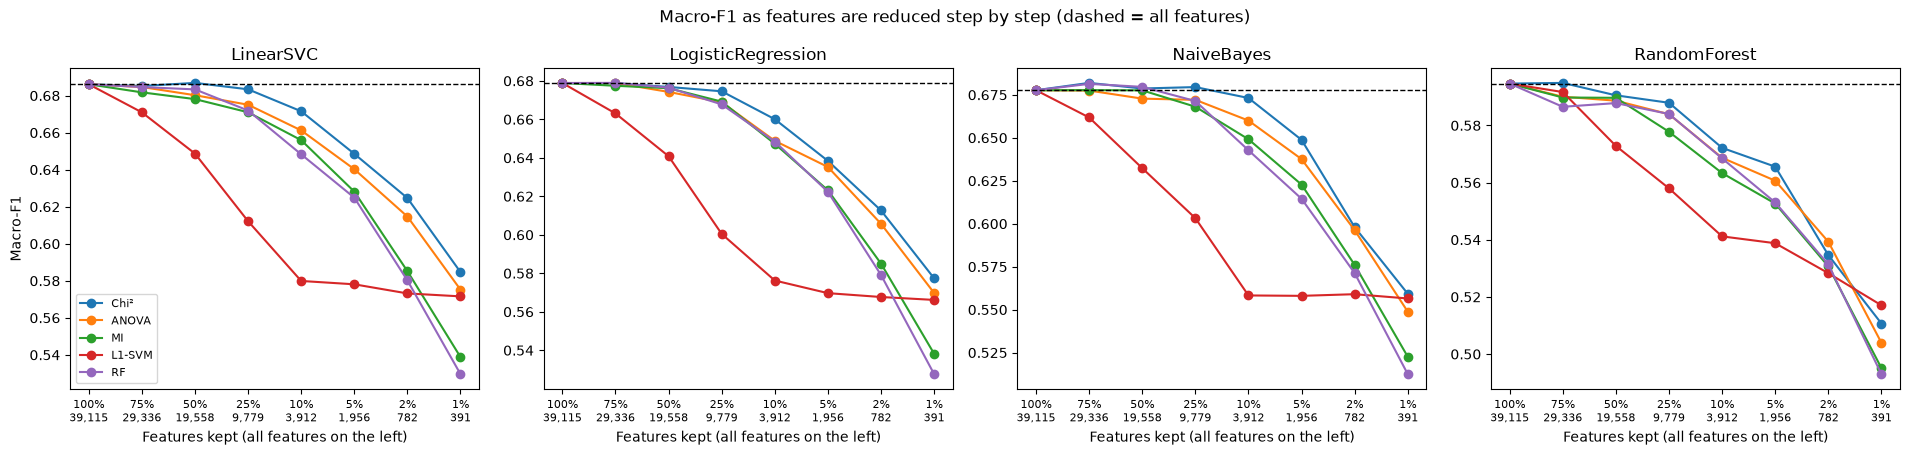

In [12]:
ev.fig_k_sweep(df, path=f"{FIG}/05_reduction_ladder.png", show=True);

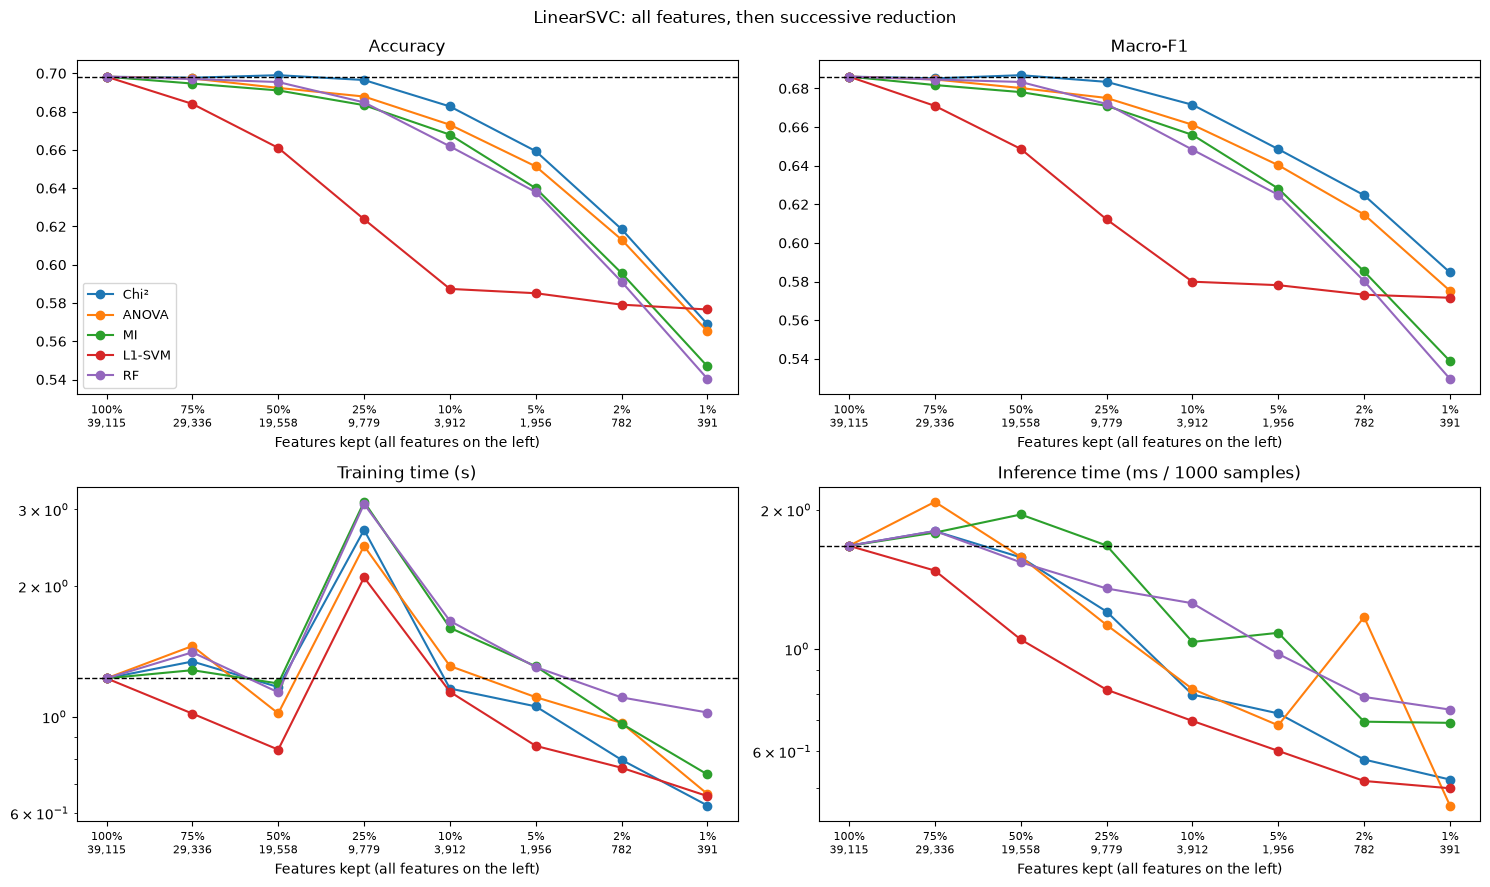

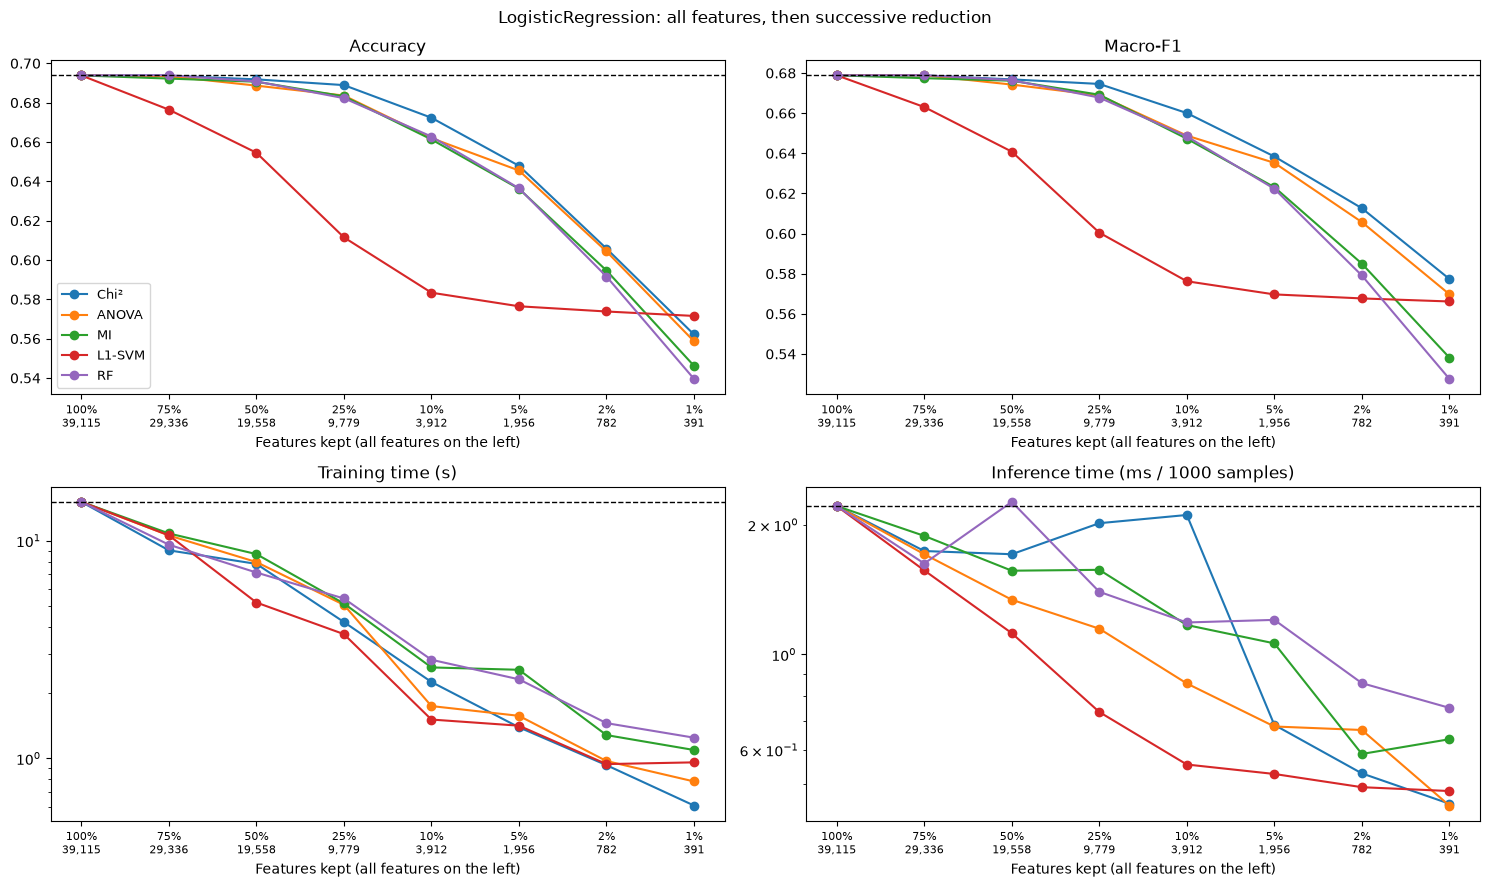

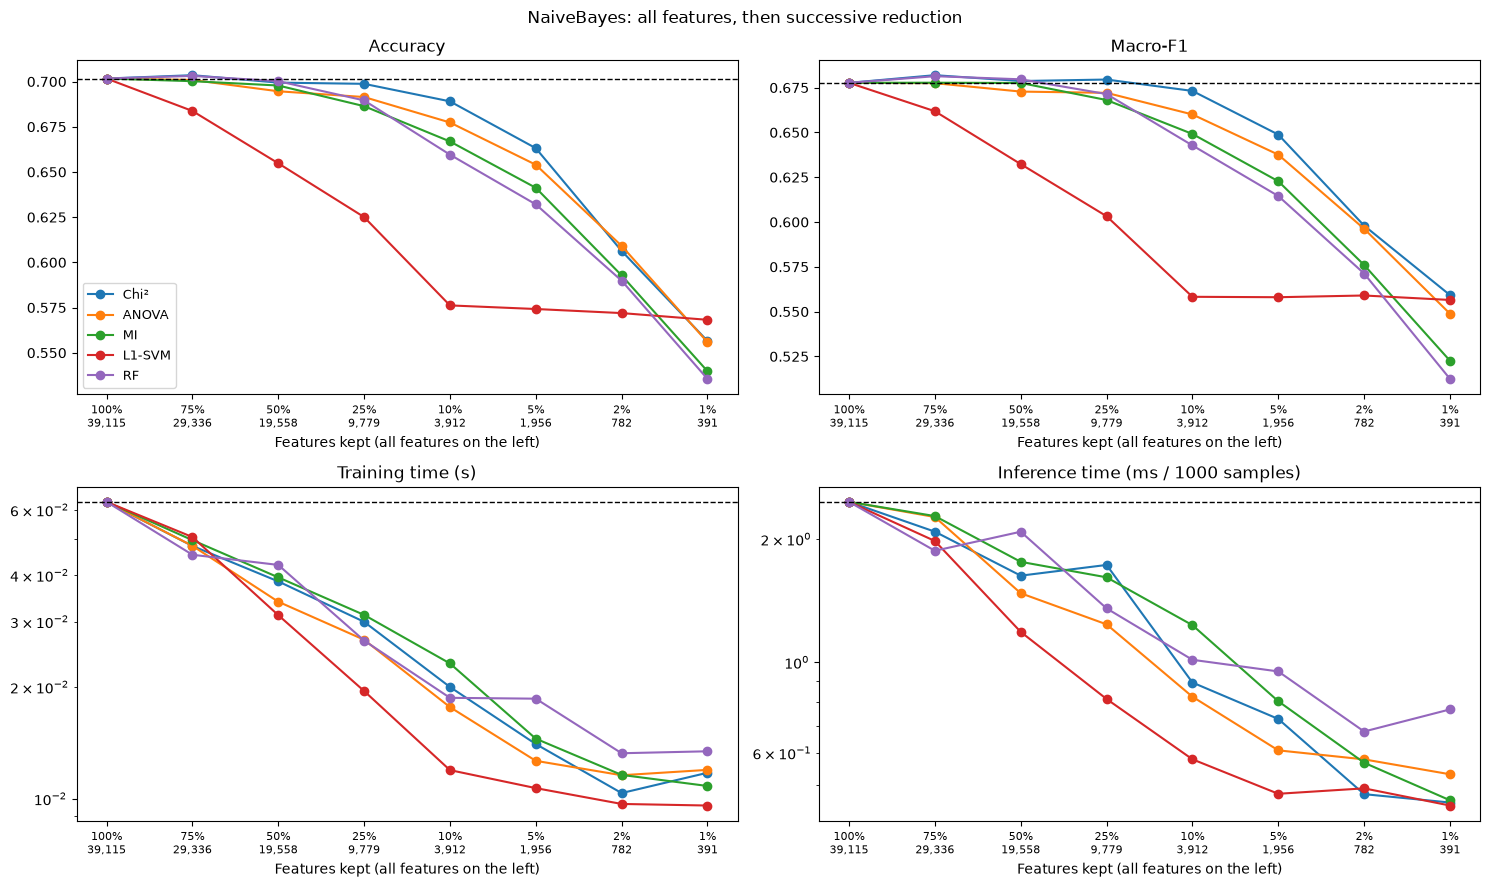

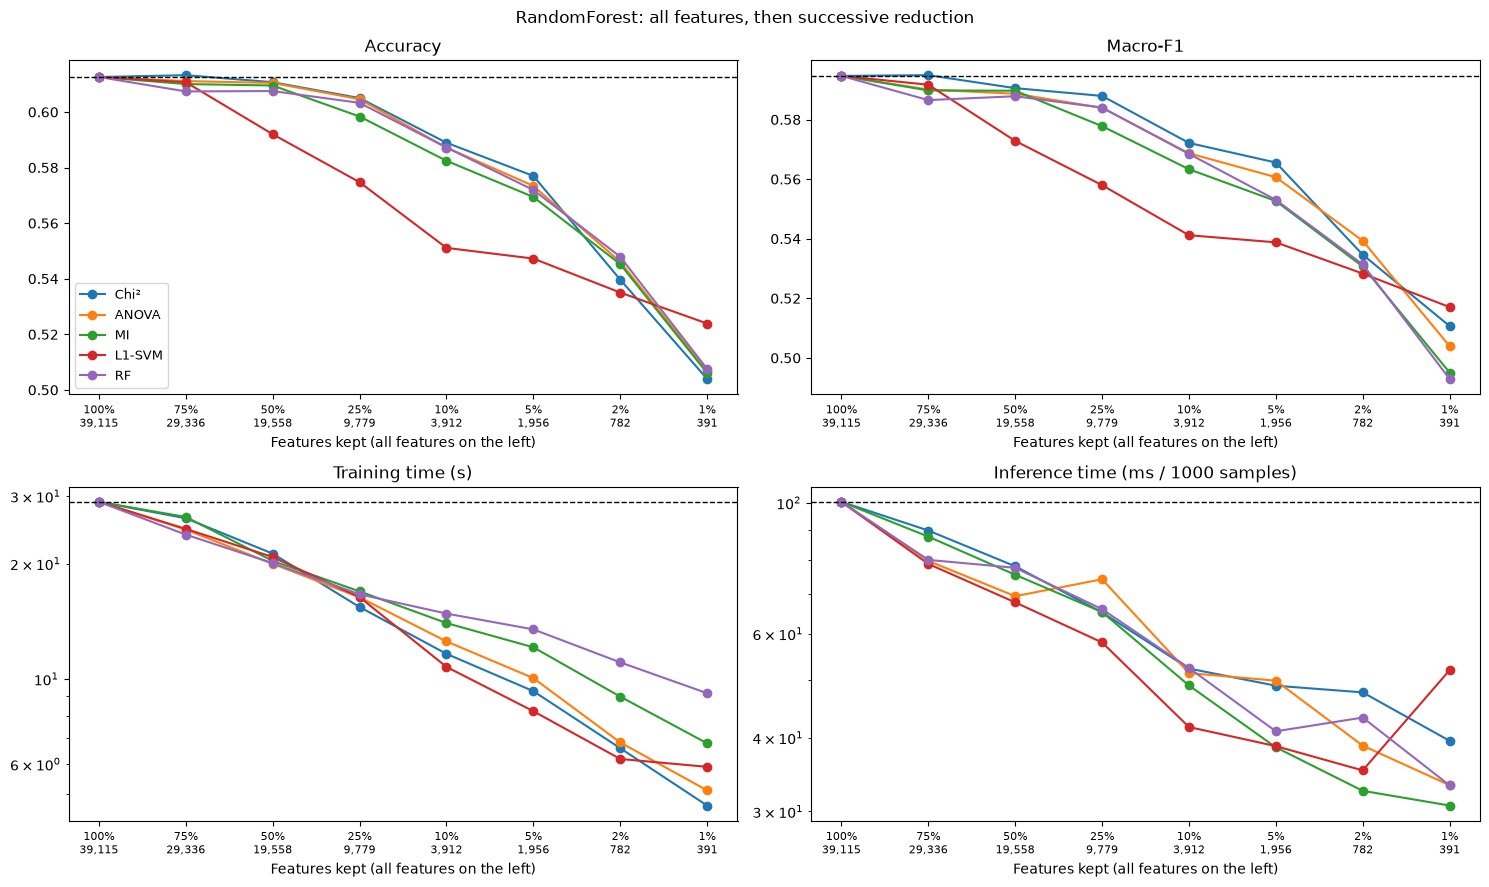

In [13]:
for mod in MODELS:
    ev.fig_ladder(df, mod, f"{FIG}/10_ladder_{mod}.png", show=True)

## 7. What do the methods select?

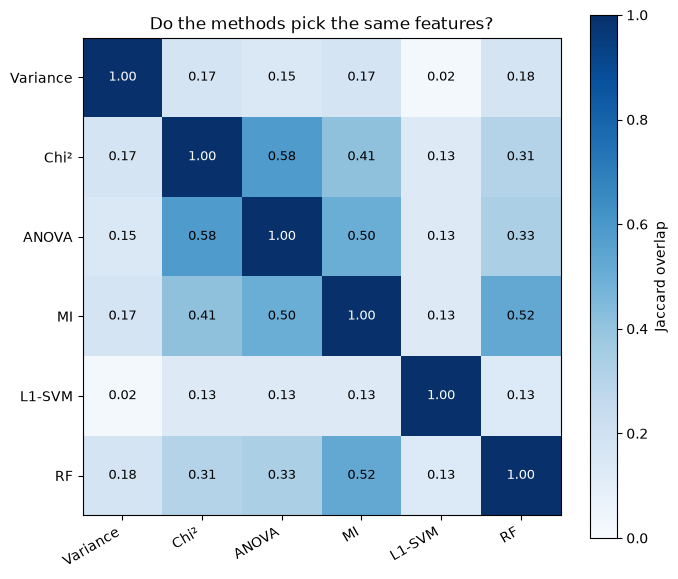

In [14]:
ev.fig_overlap(indices, f"{FIG}/07_feature_overlap.png", show=True);

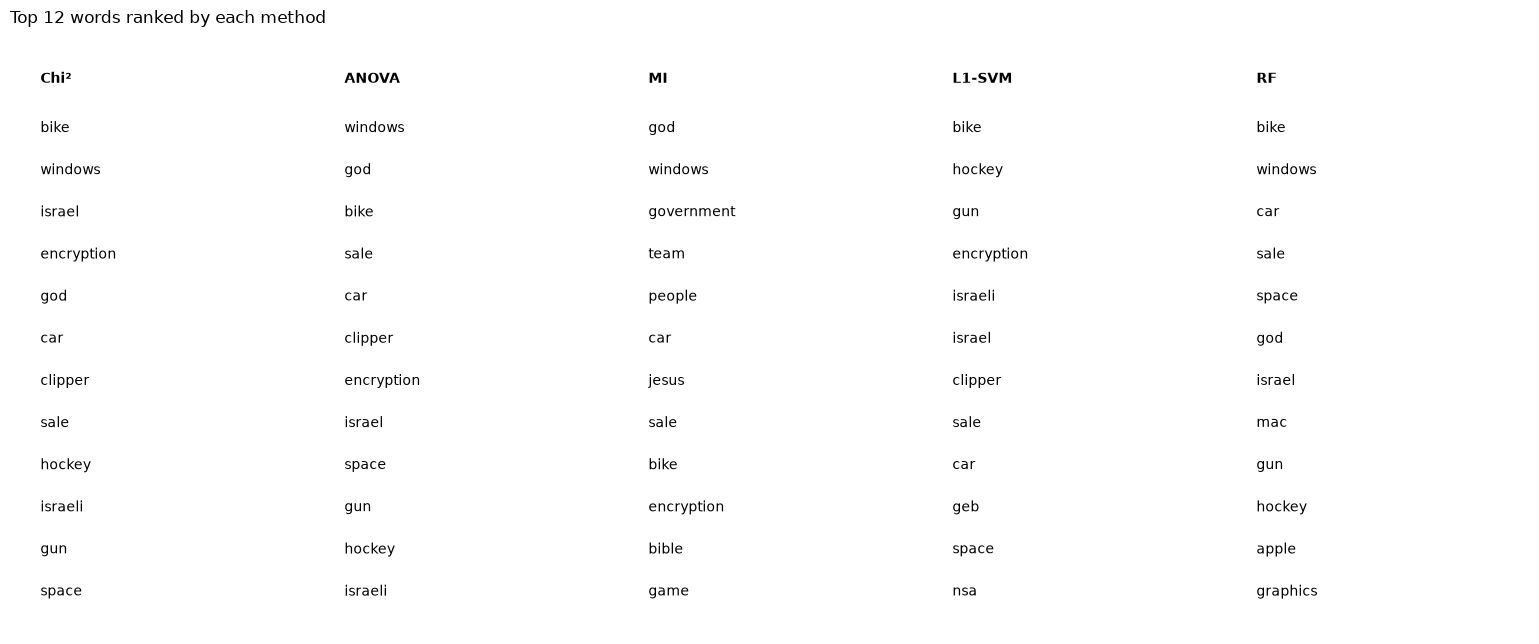

In [15]:
ev.fig_top_words(scores, data["feature_names"], path=f"{FIG}/08_top_words.png", show=True);

## 8. Interesting / failure cases: per-class effects

Best selected setup for LinearSVC (by Macro-F1): Variance Threshold


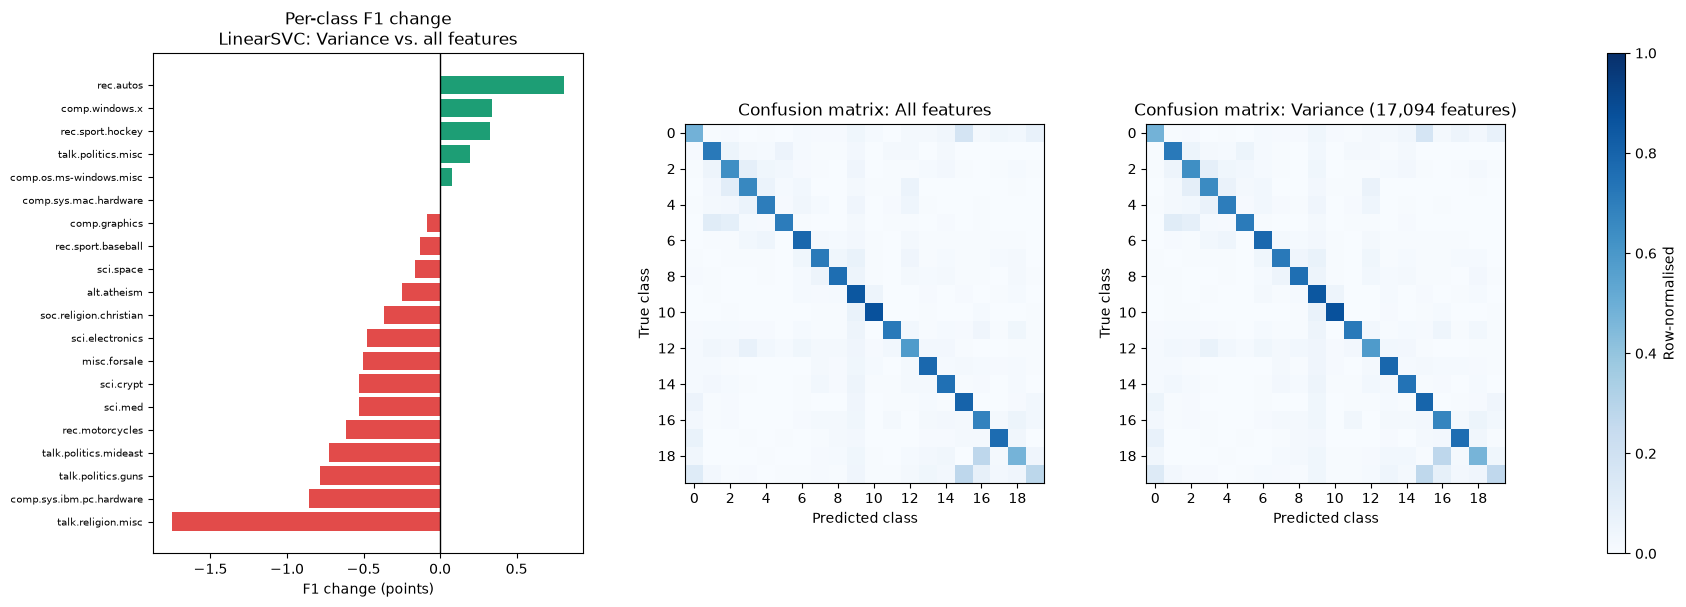

In [16]:
fig, best = ev.fig_per_class_confusion(data, indices, df, path=f"{FIG}/09_per_class_confusion.png", show=True)
print("Best selected setup for LinearSVC (by Macro-F1):", best)

## 9. Verdict: efficiency gain without losing performance?
`Yes` = Accuracy and Macro-F1 each within 1 point of all features **and** training >= 1.1x faster.

In [17]:
verdict = main[main.Method != ev.BASELINE].pivot_table(index="Model", columns="Method",
                                                       values="Verdict", aggfunc="first")
verdict[[m for m in ALL_METHODS if m in verdict.columns]]

Method,Variance Threshold,Chi-square,ANOVA F-test,Mutual Information,L1-SVM,Random Forest
Model,,,,,,
LinearSVC,Yes,No,No,No,No,No
LogisticRegression,Yes,No,No,No,No,No
NaiveBayes,Yes,No,No,No,No,No
RandomForest,Yes,No,No,No,No,No


In [18]:
cols = ["Model", "Setup", "Features", "Feature Reduction (%)", "Acc Change (pts)", "F1 Change (pts)",
        "Train Speedup (x)", "Inference Speedup (x)", "Total Speedup incl. selection (x)", "Verdict"]
main[main.Method != ev.BASELINE][cols].round(3)

,Model,Setup,Features,Feature Reduction (%),Acc Change (pts),F1 Change (pts),Train Speedup (x),Inference Speedup (x),Total Speedup incl. selection (x),Verdict
4,LinearSVC,Variance Threshold (var > 1e-05),17094,56.298,-0.266,-0.301,1.109,0.988,0.976,Yes
5,LogisticRegression,Variance Threshold (var > 1e-05),17094,56.298,-0.266,-0.218,2.148,1.362,2.103,Yes
6,NaiveBayes,Variance Threshold (var > 1e-05),17094,56.298,-0.066,0.390,1.791,1.470,0.340,Yes
7,RandomForest,Variance Threshold (var > 1e-05),17094,56.298,-0.425,-0.553,1.472,1.308,1.461,Yes
8,LinearSVC,Chi-square (k=3000),3000,92.330,-2.031,-1.879,1.216,2.376,1.119,No
9,LogisticRegression,Chi-square (k=3000),3000,92.330,-2.642,-2.264,10.497,3.028,9.893,No
10,NaiveBayes,Chi-square (k=3000),3000,92.330,-1.832,-0.950,4.086,3.018,0.612,No
11,RandomForest,Chi-square (k=3000),3000,92.330,-2.655,-2.425,2.691,2.073,2.670,No
12,LinearSVC,ANOVA F-test (k=3000),3000,92.330,-3.412,-3.438,1.023,1.958,0.943,No
13,LogisticRegression,ANOVA F-test (k=3000),3000,92.330,-3.771,-3.478,5.780,2.616,5.564,No
